# v003 ISO/TS 16281 load zone: AxisForge's bearing load distribution against r03

**Question.** Does AxisForge's ISO/TS 16281 solver put the right load on each ball of a rigid-ring bearing?
Judged: a 6210-like deep groove ball bearing under a radial load, diametral clearance 0-60 um, `F_r` 1-10 kN,
against r03 (Harris ch. 7 with the same `c_p` and clearance) element by element, and `c_p` against the Hertz
series of the two contacts (r02 `hertz_full`, r03 Eq. 7.6). Angular contact and roller bearings: RECORD (r03
keeps the contact angle fixed and has no roller profile).

**Literature.** Hamrock 1983 sec. 14.2 (PDF p. 44-46): `F_max` 4513 N, `delta` 5.438e-5 m. Hernot 2000 Table 1
(PDF p. 3): judges r03 only (its geometry is not printed).

**Criteria (README section 6, fixed before the run).** C1-C6 within 1e-5 (AxisForge's root tolerance 1e-6,
one order above; C5 restates C4, C6 is AxisForge's self-consistency); C7 `c_p` within 0.5 %; Hamrock `F_max` 1 %, `delta` 2 %; Hernot to half a unit of the printed
digits; sign check (R-003) RECORD.

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v000_axisforge.v003_iso16281_load_zone import study

out = study.run()
fig = {p.stem.removeprefix("v003_"): p for p in out["figures"]}

## 1. Ball loads around the bearing (6210, F_r 5000 N)
Filled markers: AxisForge's balls; lines: r03 at AxisForge's own `delta_r` (local azimuth, 0 on the load line).
Each marker sits on its line. At zero clearance the zone ends at +-90 deg and the line is `Q_max cos^1.5`
(dotted, same curve); with 40 um the zone narrows (`psi_l` about 70 deg) and `Q_max` rises.

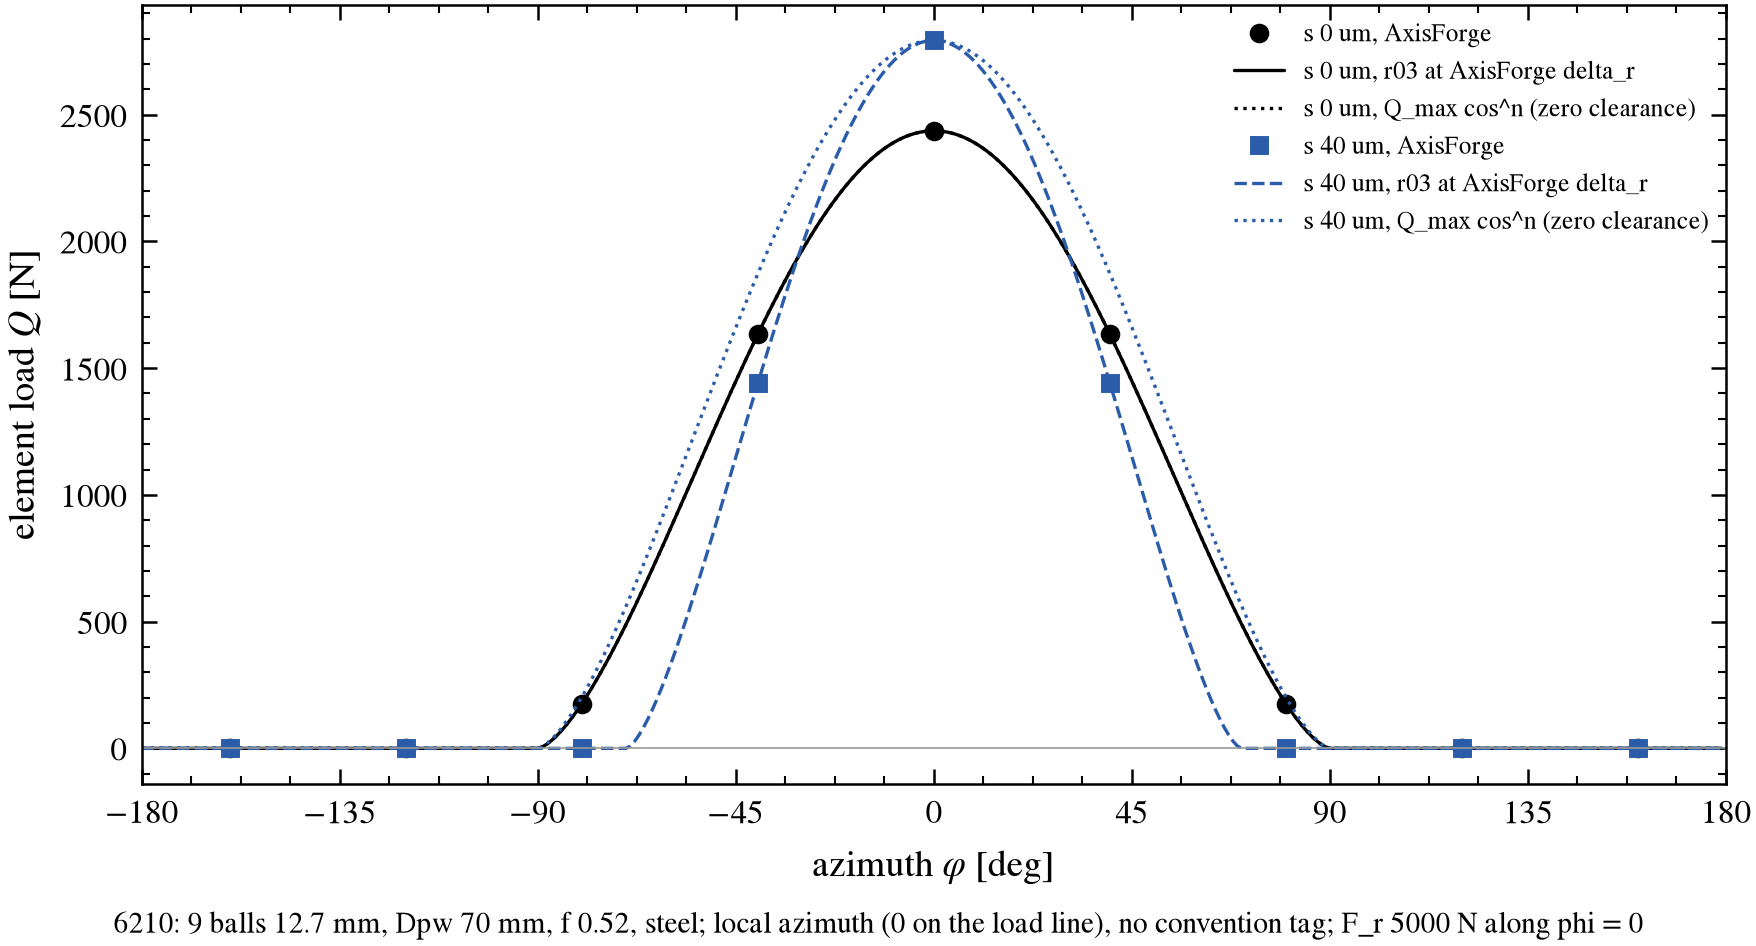

In [2]:
display(Image(filename=str(fig["bearing_loads_element_loads_6210"])))

## 2. Judged records C1-C7 and their error against the clearance
The tolerance (1e-5 = 1e-3 %) is the dashed line; C1 is exact to round-off (drawn at the 1e-10 % floor).

s [um]  F_r [N]  id                                                          quantity    AxisForge        judge    rel err    tol  verdict
------  -------  --  ----------------------------------------------------------------  -----------  -----------  ---------  -----  -------
     0     1000  C1                                          Q_j at AxisForge delta_r      487.245      487.245   5.02e-15  1e-05     PASS
     0     1000  C2                                             Q_j, r03 solve at F_r      487.245      487.245   9.25e-14  1e-05     PASS
     0     1000  C3                                                             Q_max      487.245      487.245  -9.25e-14  1e-05     PASS
     0     1000  C4                                                           delta_r  1.18934e-05  1.18934e-05  -6.46e-14  1e-05     PASS
     0     1000  C5  eps = (1 - s/(2 delta_r))/2 from AxisForge delta_r (restates C4)          0.5          0.5   0.00e+00  1e-05     PASS
     0     1000  C6   sum Q

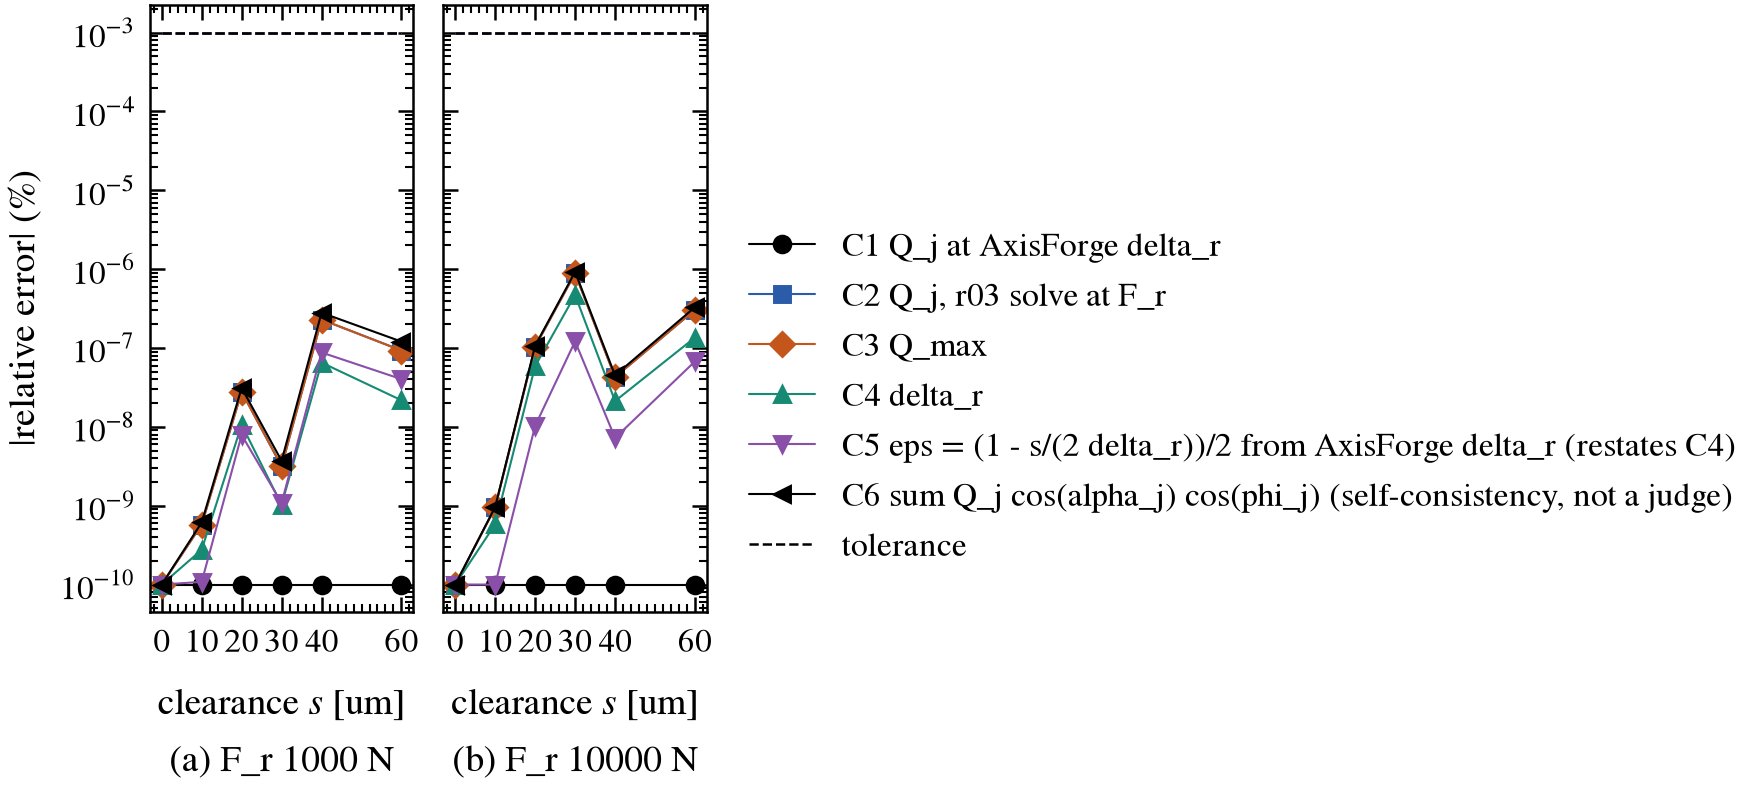

In [3]:
judged = [r for r in out["check"] if r["Fr_N"] in (1000.0, 10000.0)]
print(format_table((("s_um", "s [um]", ".0f"), ("Fr_N", "F_r [N]", ".0f"), ("id", "id", "s"),
                    ("quantity", "quantity", "s"), ("measured", "AxisForge", ".6g"), ("reference", "judge", ".6g"),
                    ("rel_err", "rel err", ".2e"), ("tol", "tol", ".0e"), ("verdict", "verdict", "s")), judged))
display(Image(filename=str(fig["contact_relative_errors_6210"])))

## 3. Load distribution factor and Stribeck's number against the clearance
AxisForge (markers) on r03 (lines). At `s = 0` every load meets `eps = 0.5` and `Z Q_max / F_r` = 4.38
(9 balls; Harris's 4.37 = `1/J_r(0.5)`, the continuous form, is the dotted line); clearance narrows the zone (`eps` falls) and
raises `Q_max`, more at light load.

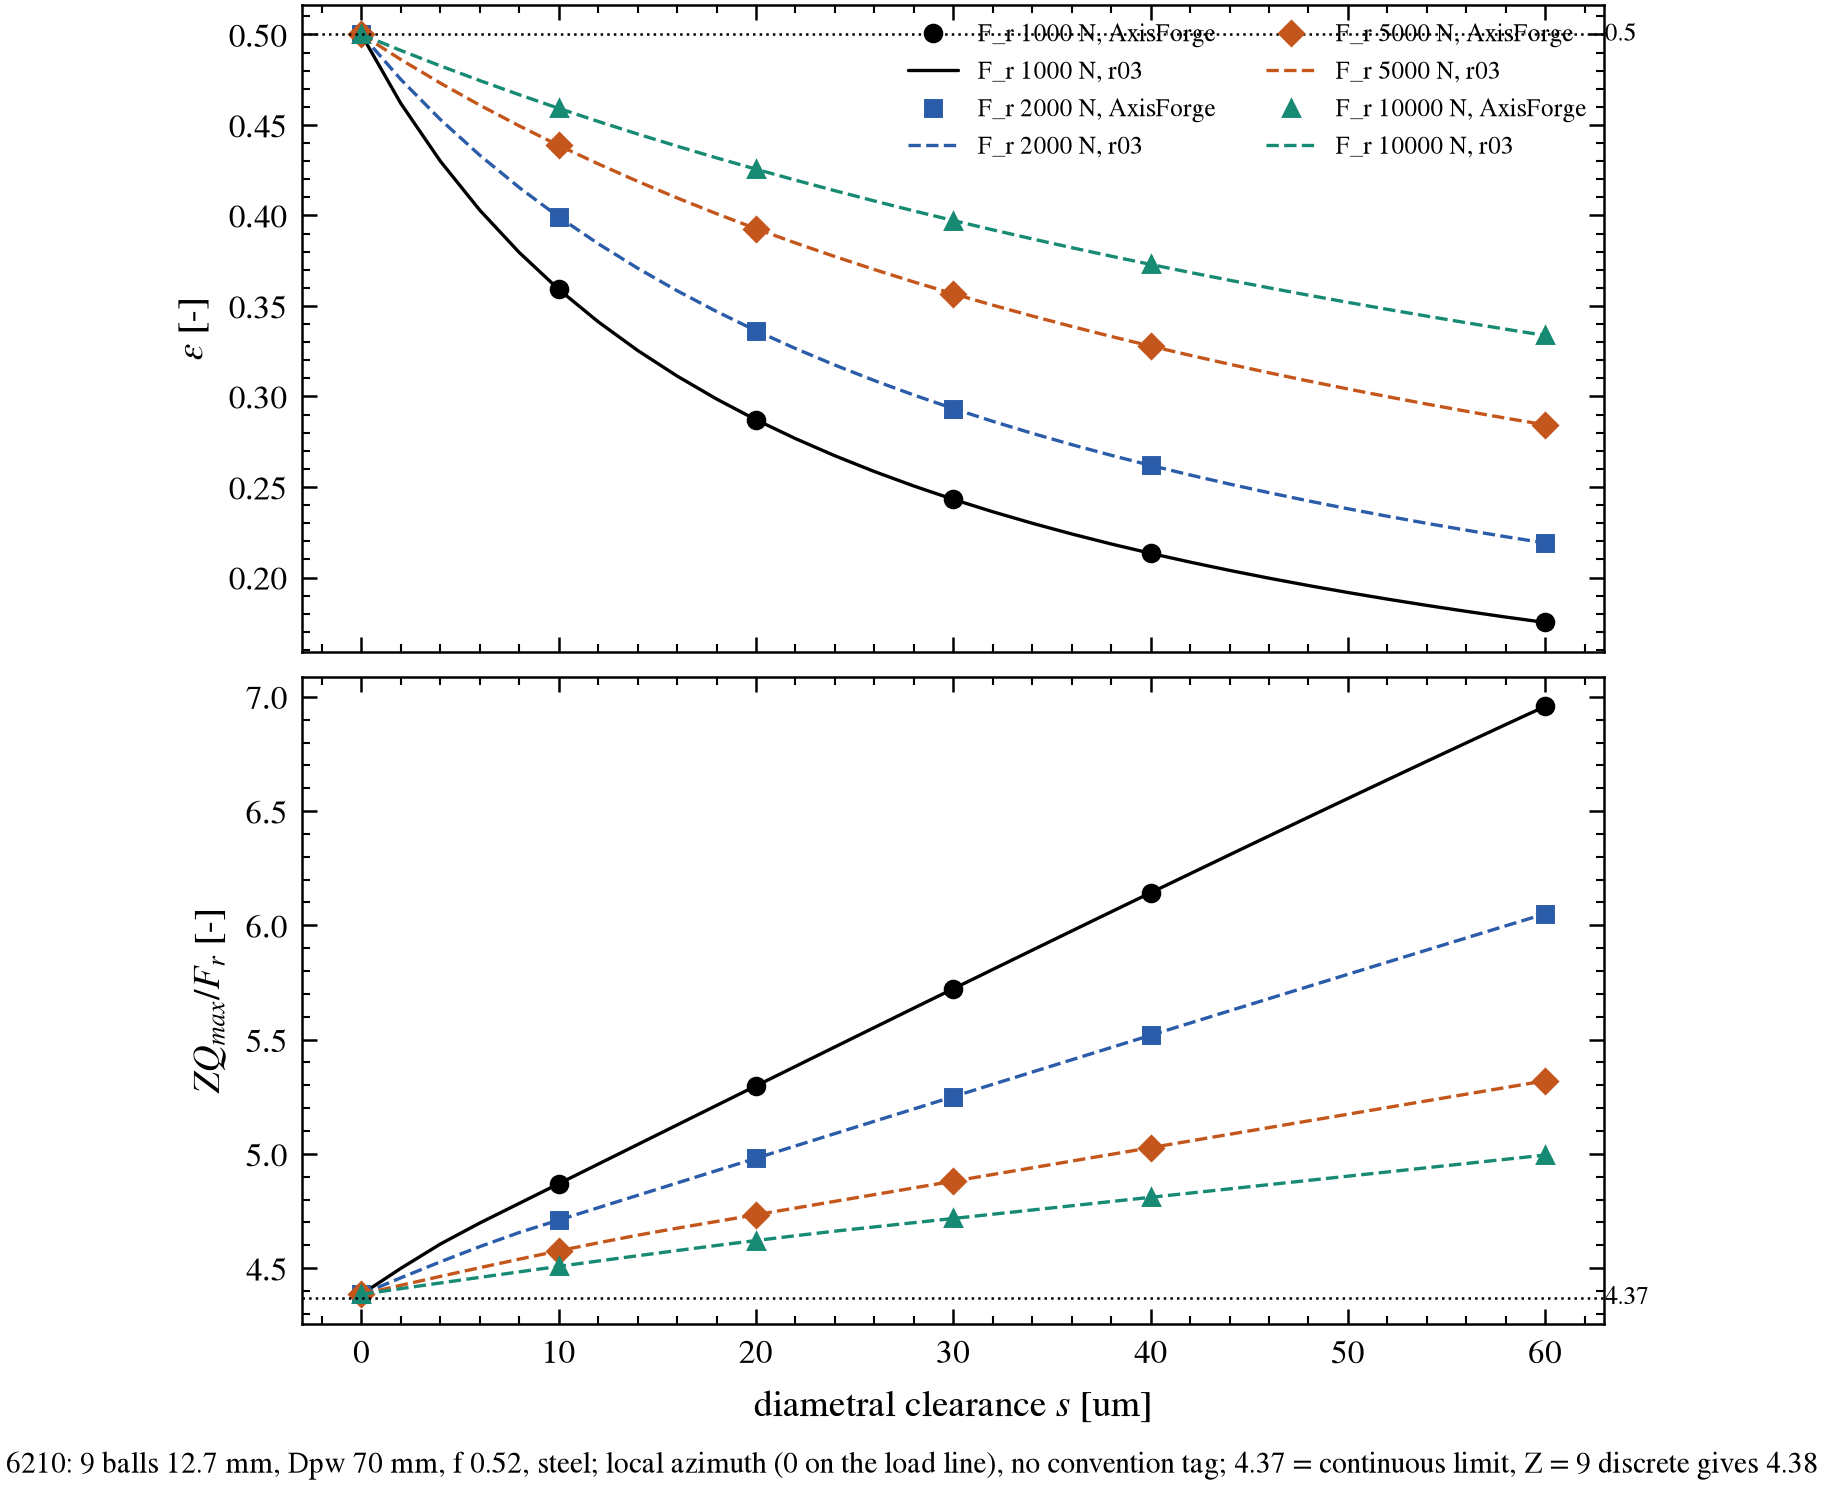

In [4]:
display(Image(filename=str(fig["bearing_loads_load_zone_sweep_6210"])))

## 4. Literature: Hamrock 1983 sec. 14.2 (AxisForge) and Hernot 2000 (r03)

                  source  id                       quantity     computed    printed    rel err      tol  verdict                 judge
------------------------  --  -----------------------------  -----------  ---------  ---------  -------  -------  --------------------
hamrock1983_sec14_2_dgbb  L1                          F_max      4522.54       4513   2.11e-03  1.0e-02     PASS  AxisForge vs printed
hamrock1983_sec14_2_dgbb  L2  delta of the most loaded ball  5.42755e-05  5.438e-05  -1.92e-03  2.0e-02     PASS  AxisForge vs printed
hamrock1983_sec14_2_dgbb  L3              Z = F_max n / F_r      4.57335      4.564   2.05e-03        -   RECORD  AxisForge vs printed
     hernot2000_218_acbb  L4                          Q_max       6543.9       6544  -1.50e-05  7.6e-05     PASS        r03 vs printed
     hernot2000_218_acbb  L5                        delta_a  -0.00925715   -0.00926  -3.08e-04  5.4e-04     PASS        r03 vs printed
     hernot2000_218_acbb  L6                        del

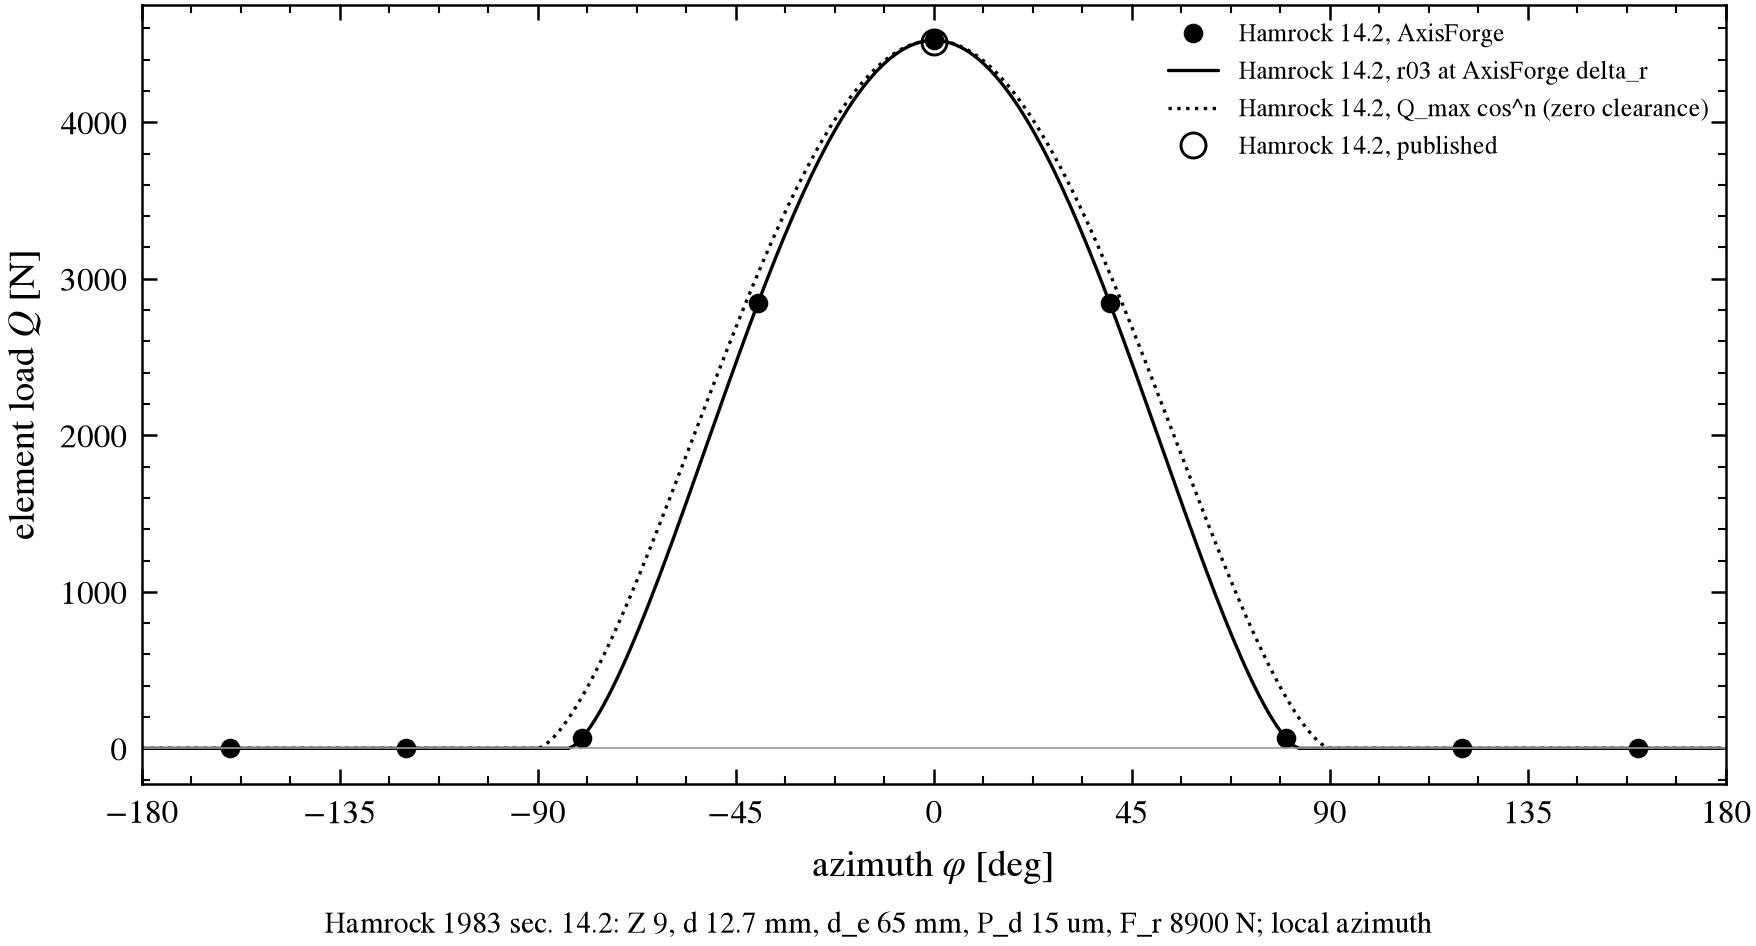

In [5]:
print(format_table((("source", "source", "s"), ("id", "id", "s"), ("quantity", "quantity", "s"),
                    ("measured", "computed", ".6g"), ("reference", "printed", ".6g"), ("rel_err", "rel err", ".2e"),
                    ("tol", "tol", ".1e"), ("verdict", "verdict", "s"), ("judge", "judge", "s")), out["literature"]))
display(Image(filename=str(fig["bearing_loads_element_loads_hamrock1983"])))

## 5. RECORD: angular contact (7210, alpha_0 40 deg) and cylindrical roller (NU210)
AxisForge's contact angle follows the load (`alpha_j` 40.2-46.4 deg over the sweep); r03 keeps 40 deg, so the two
part by an amount that grows with the thrust (a few % in `Q_max`, more in `delta_r` and `eps`). The roller
bearing differs by its ISO/TS 16281 profile in laminae (`delta_r` about 19 %). No verdict.

                  bearing  id                                                          quantity   AxisForge   r03 / r02    rel err  verdict
-------------------------  --  ----------------------------------------------------------------  ----------  ----------  ---------  -------
 7210 Fr 3000 N Fa 4000 N  C1                                          Q_j at AxisForge delta_r      1178.5      1178.3   7.91e-03   RECORD
 7210 Fr 3000 N Fa 4000 N  C2                                             Q_j, r03 solve at F_r      1178.5      1173.1   1.15e-02   RECORD
 7210 Fr 3000 N Fa 4000 N  C3                                                             Q_max      1178.5      1173.1   4.64e-03   RECORD
 7210 Fr 3000 N Fa 4000 N  C4                                                           delta_r  1.5304e-05   1.473e-05   3.90e-02   RECORD
 7210 Fr 3000 N Fa 4000 N  C5  eps = (1 - s/(2 delta_r))/2 from AxisForge delta_r (restates C4)     0.91331     0.94609  -3.46e-02   RECORD
 7210 Fr 3000 N Fa 4

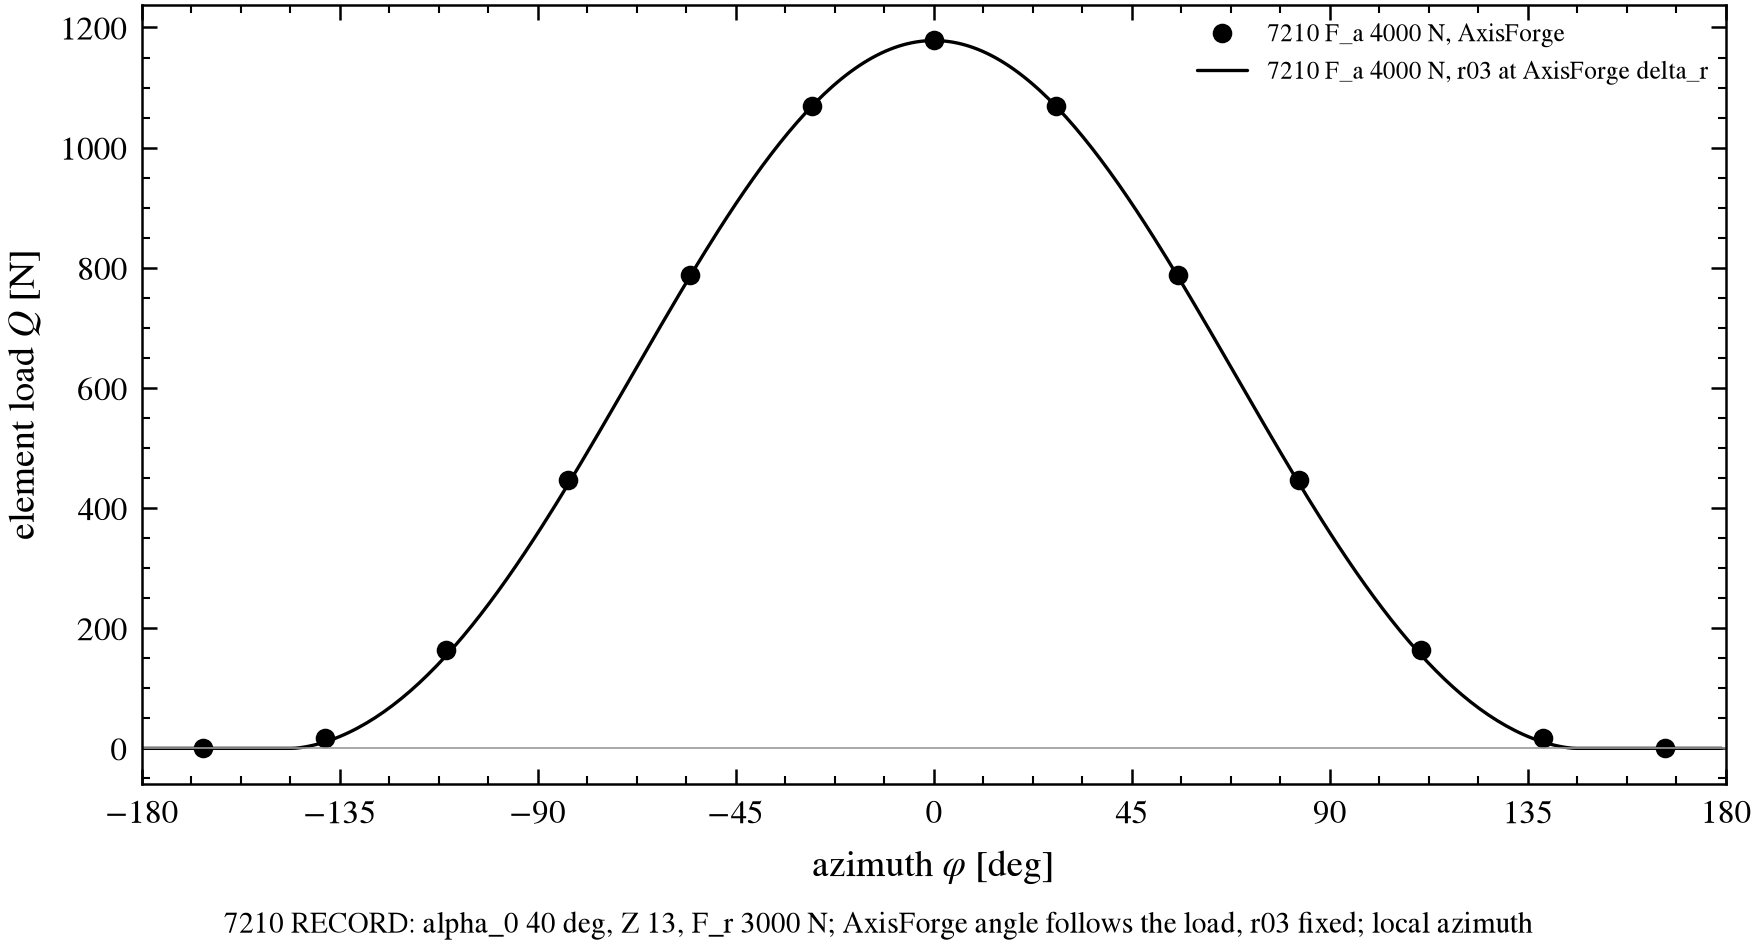

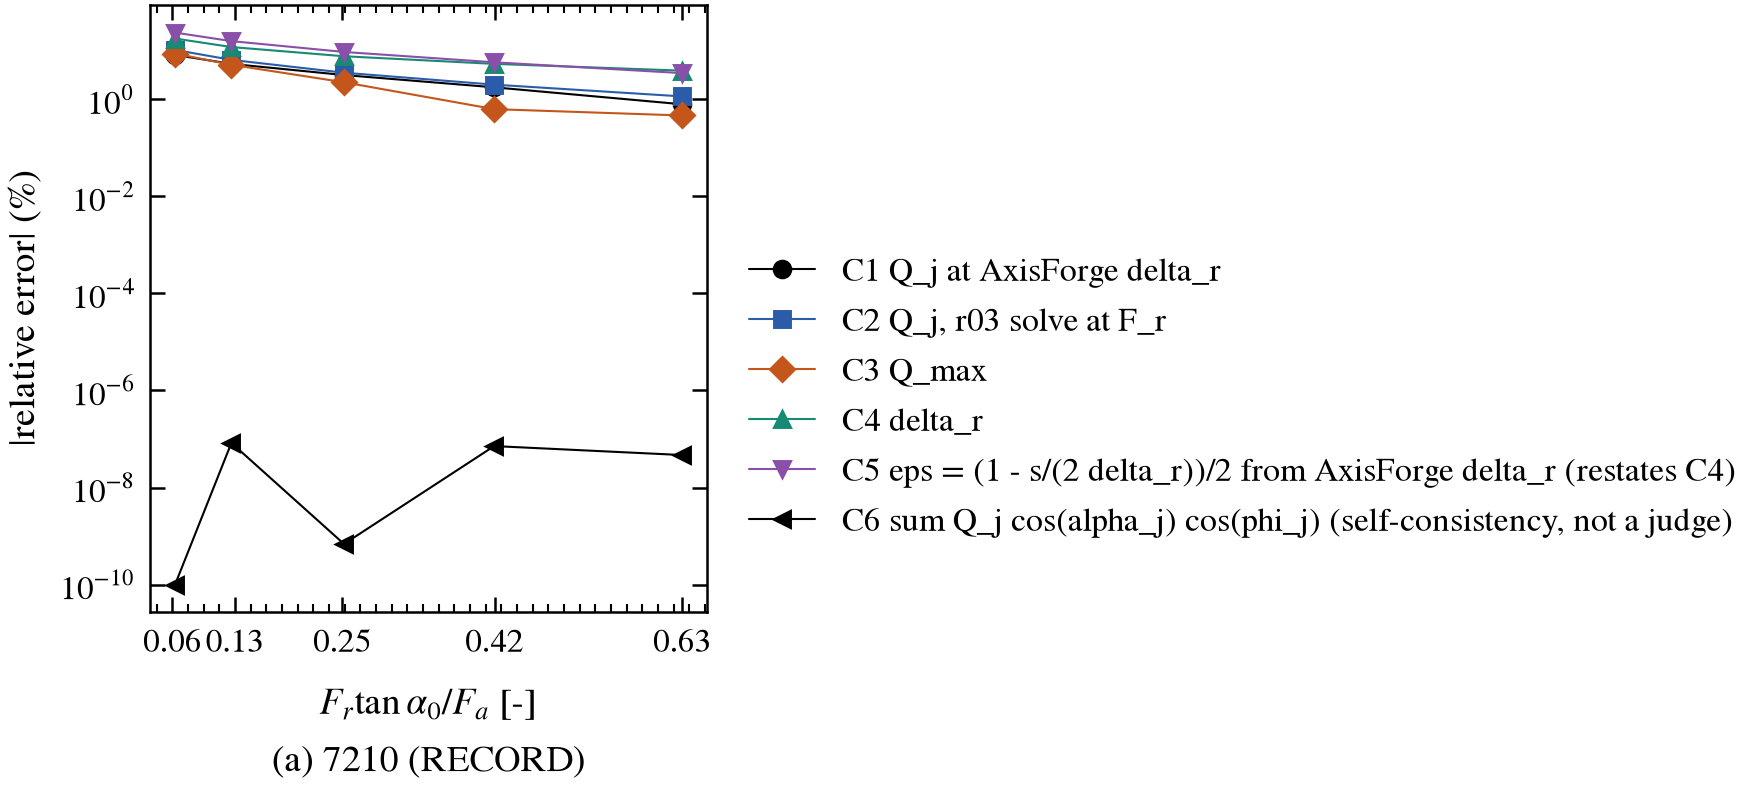

In [6]:
print(format_table((("label", "bearing", "s"), ("id", "id", "s"), ("quantity", "quantity", "s"),
                    ("measured", "AxisForge", ".5g"), ("reference", "r03 / r02", ".5g"), ("rel_err", "rel err", ".2e"),
                    ("verdict", "verdict", "s")), out["acbb"] + out["crb"]))
display(Image(filename=str(fig["bearing_loads_element_loads_7210"])))
display(Image(filename=str(fig["contact_relative_errors_7210"])))

## 6. First check (R-003): where does Q_max land in the global frame?
A shaft on two 6210 with one radial load (-Z, and 300 deg; `F_a = 0`, so only the radial half of R-003 is
exercised). The shaft pushes the inner ring along the load. The evidence is two numbers: the most loaded ball is
**180 deg** from the load on the shaft, and the inner-ring balance gives **`|r| / F_r = 2`** (`Q_max` at `phi_Fr`
holds by construction, R-396). The node force fed to the solver is the support force on the shaft. Evidence on
R-003 / R-396, recorded, not changed: **convention-dependent (R-003)**.

load theta [deg]  bearing  load dir. [deg]  phi_Fr [deg]  phi(Q_max) [deg]  offset [deg]  |r|/F_r                           tag
----------------  -------  ---------------  ------------  ----------------  ------------  -------  ----------------------------
             270   6210_A            180.0           0.0               0.0        -180.0    2.000  convention-dependent (R-003)
             270   6210_B            180.0           0.0               0.0        -180.0    2.000  convention-dependent (R-003)
             300   6210_A            150.0         -30.0             330.0         180.0    2.000  convention-dependent (R-003)
             300   6210_B            150.0         -30.0             330.0        -180.0    2.000  convention-dependent (R-003)


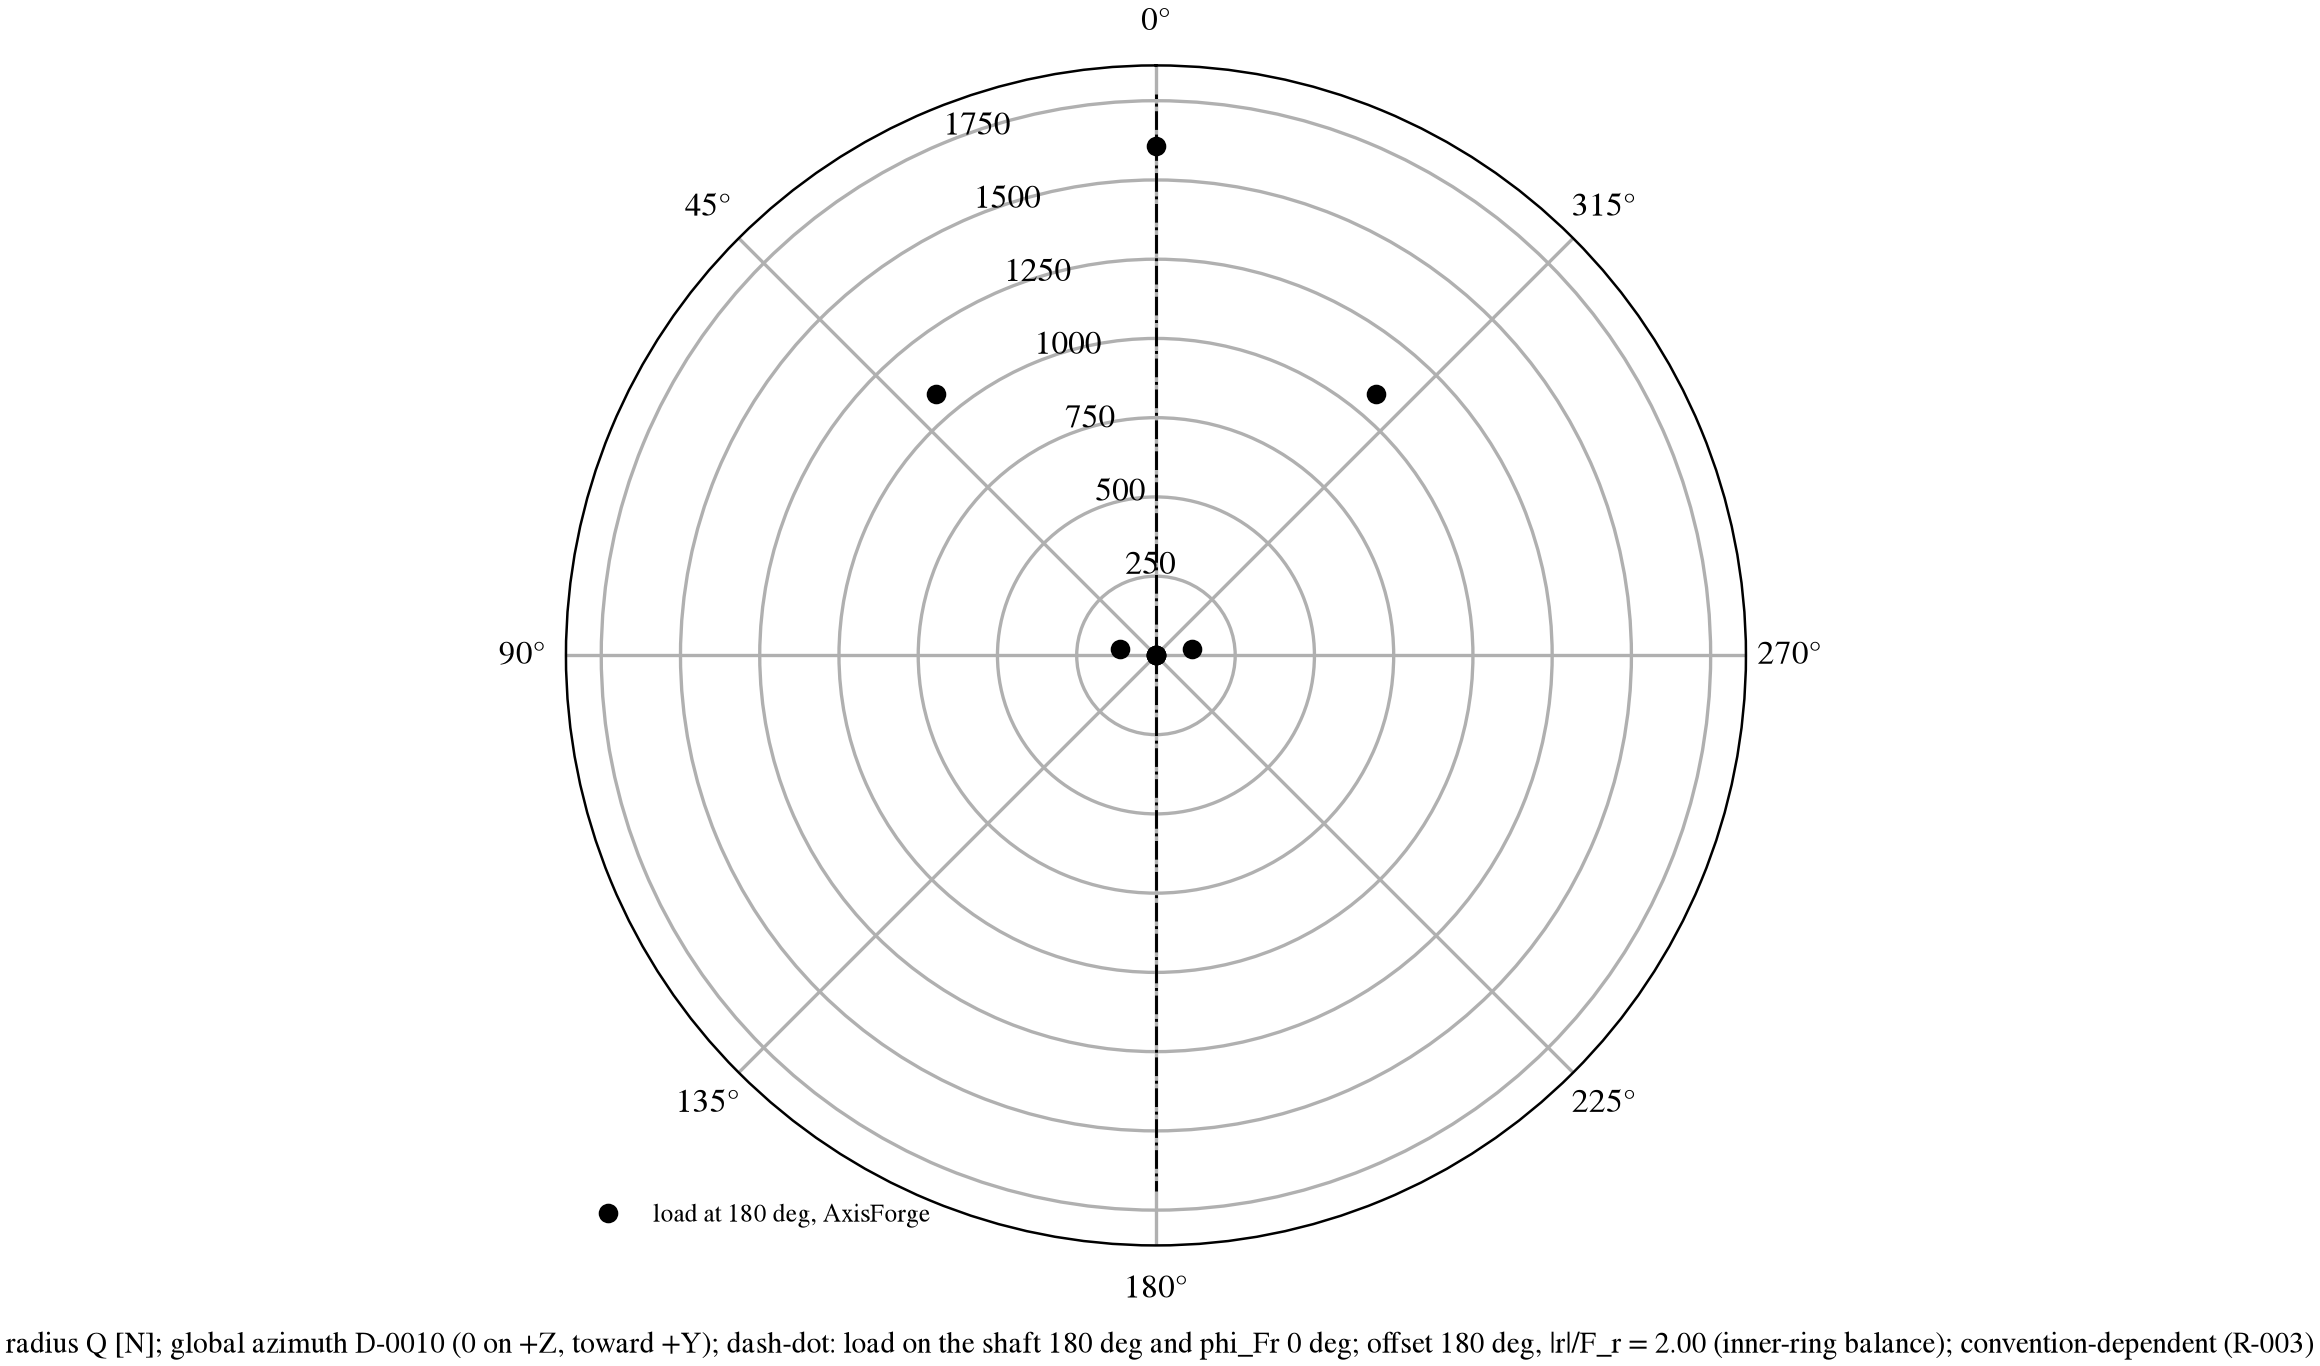

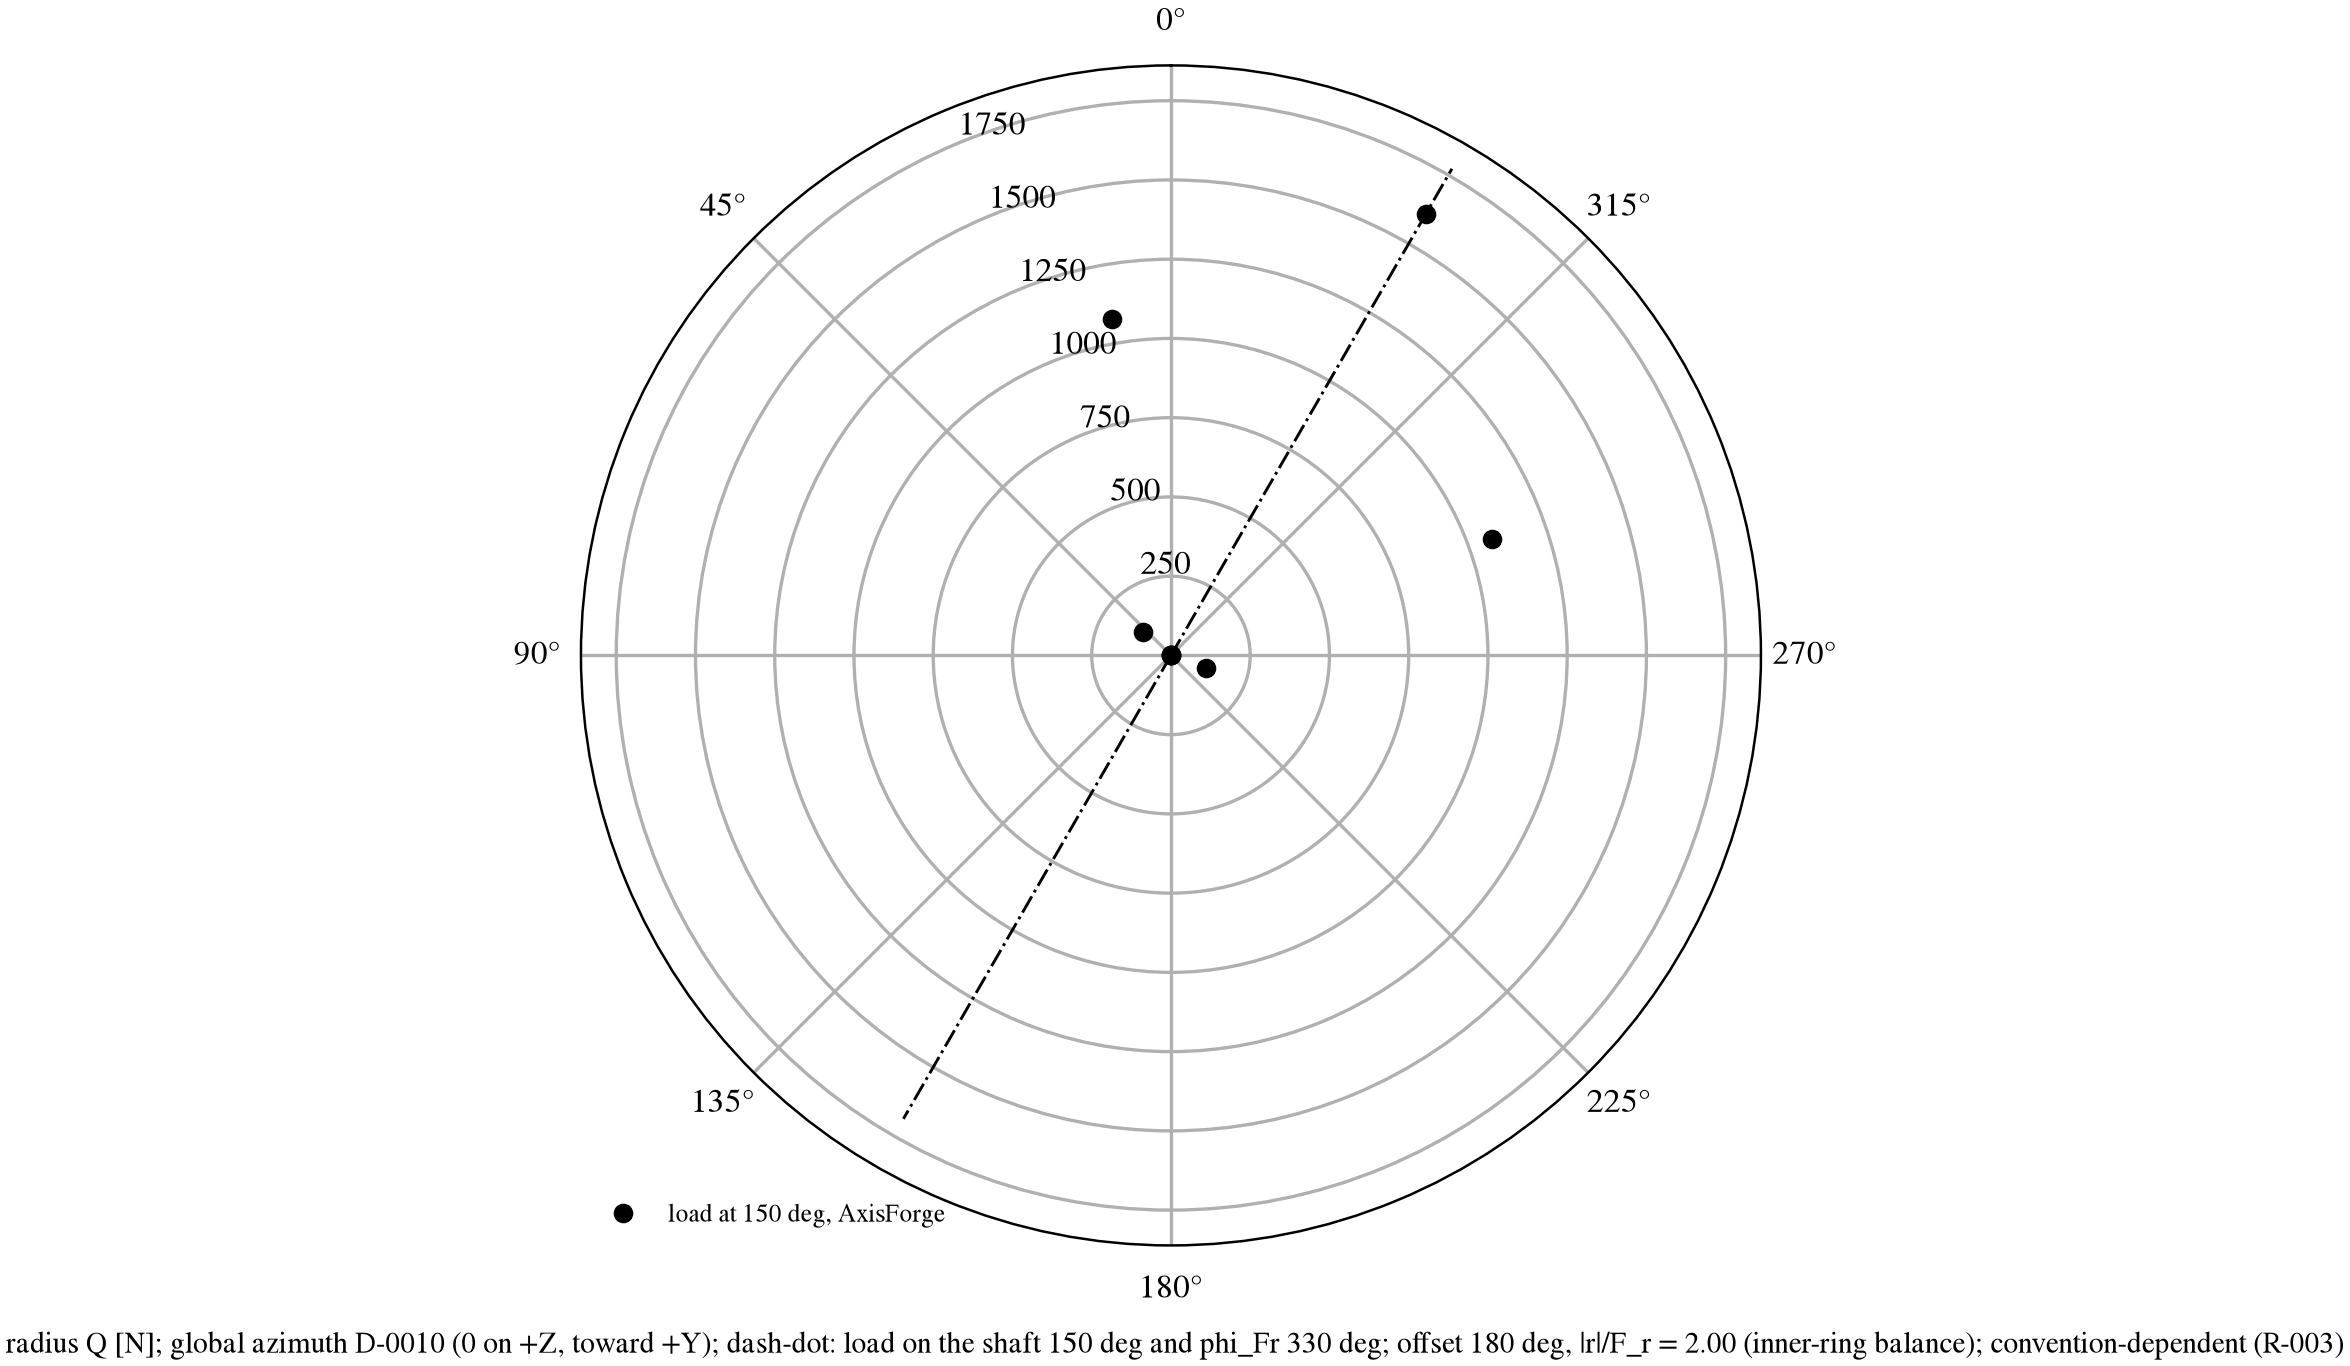

In [7]:
print(format_table((("theta_deg", "load theta [deg]", ".0f"), ("label", "bearing", "s"),
                    ("phi_load_deg", "load dir. [deg]", ".1f"), ("phi_Fr_deg", "phi_Fr [deg]", ".1f"),
                    ("phi_Qmax_global_deg", "phi(Q_max) [deg]", ".1f"), ("offset_deg", "offset [deg]", ".1f"),
                    ("residual_over_Fr", "|r|/F_r", ".3f"), ("tag", "tag", "s")), out["sign"]))
for t in (270, 300):
    display(Image(filename=str(fig[f"bearing_loads_element_loads_sign_check_{t}"])))

## 7. AxisForge's solver (SciPy root, hybr / lm; not Newton)

In [8]:
s = out["solver"]
print(f"{len(s)} solves, all ok: {all(r['ok'] for r in s)}, largest residual {max(r['residual_N'] for r in s):.2e} N, "
      f"function evaluations {min(r['n_iter'] for r in s)}-{max(r['n_iter'] for r in s)}")

30 solves, all ok: True, largest residual 1.65e-04 N, function evaluations 11-29
